#Importación de la base y de librerías

In [ ]:
import pandas as pd
import sklearn as sk
from sklearn import model_selection
from sklearn import tree
from sklearn import metrics
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [ ]:
url = "https://drive.google.com/uc?id=1jH-1R7XygKzX87f-mubxurC_6toeiv33"

df = pd.read_csv(url)

df.head()

,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),Triceps skin fold thickness (mm),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years),Class variable (0 or 1)
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


#Primeras observaciones de la base

##Cantidad de filas y columnas

In [ ]:
df.shape

(768, 9)

La base cuenta con 768 registros de pacientes y 9 atributos, en donde se destaca la variable objetivo "Class variable" (si el paciente tiene o no diabetes).

##Primeros y últimos elementos

In [ ]:
df.head(10)

,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),Triceps skin fold thickness (mm),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years),Class variable (0 or 1)
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [ ]:
df.tail(10)

,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),Triceps skin fold thickness (mm),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years),Class variable (0 or 1)
758,1,106,76,0,0,37.5,0.197,26,0
759,6,190,92,0,0,35.5,0.278,66,1
760,2,88,58,26,16,28.4,0.766,22,0
761,9,170,74,31,0,44.0,0.403,43,1
762,9,89,62,0,0,22.5,0.142,33,0
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


Renombramos las columnas


In [ ]:
df = df.rename(columns={
    "Number of times pregnant": "Pregnancies",
    "Plasma glucose concentration a 2 hours in an oral glucose tolerance test": "Glucose",
    "Diastolic blood pressure (mm Hg)": "BloodPressure",
    "Triceps skin fold thickness (mm)": "SkinThickness",
    "2-Hour serum insulin (mu U/ml)": "Insulin",
    "Body mass index (weight in kg/(height in m)^2)": "BMI",
    "Diabetes pedigree function": "DiabetesPedigreeFunction",
    "Age (years)": "Age",
    "Class variable (0 or 1)": "Outcome"
})

##Tipos de variable y frecuencia de cada variable

In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
df.dtypes

,0
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


Aquí podemos observar que todas las variables son numéricas y toman valores enteros, salvo "BMI" y "DiabetesPedigreeFunction" que toman valores con decimales.

In [ ]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


En principio no tiene elementos vacíos, pero puede haber elementos con valores nulos que no tengan sentido para la variable y que se interpreten como dato faltante.

In [ ]:
#Valores únicos de cada variable
df['Pregnancies'].unique()

array([ 6,  1,  8,  0,  5,  3, 10,  2,  4,  7,  9, 11, 13, 15, 17, 12, 14])

In [ ]:
df['Glucose'].unique()

array([148,  85, 183,  89, 137, 116,  78, 115, 197, 125, 110, 168, 139,
       189, 166, 100, 118, 107, 103, 126,  99, 196, 119, 143, 147,  97,
       145, 117, 109, 158,  88,  92, 122, 138, 102,  90, 111, 180, 133,
       106, 171, 159, 146,  71, 105, 101, 176, 150,  73, 187,  84,  44,
       141, 114,  95, 129,  79,   0,  62, 131, 112, 113,  74,  83, 136,
        80, 123,  81, 134, 142, 144,  93, 163, 151,  96, 155,  76, 160,
       124, 162, 132, 120, 173, 170, 128, 108, 154,  57, 156, 153, 188,
       152, 104,  87,  75, 179, 130, 194, 181, 135, 184, 140, 177, 164,
        91, 165,  86, 193, 191, 161, 167,  77, 182, 157, 178,  61,  98,
       127,  82,  72, 172,  94, 175, 195,  68, 186, 198, 121,  67, 174,
       199,  56, 169, 149,  65, 190])

In [ ]:
df['BloodPressure'].unique()

array([ 72,  66,  64,  40,  74,  50,   0,  70,  96,  92,  80,  60,  84,
        30,  88,  90,  94,  76,  82,  75,  58,  78,  68, 110,  56,  62,
        85,  86,  48,  44,  65, 108,  55, 122,  54,  52,  98, 104,  95,
        46, 102, 100,  61,  24,  38, 106, 114])

In [ ]:
df['SkinThickness'].unique()

array([35, 29,  0, 23, 32, 45, 19, 47, 38, 30, 41, 33, 26, 15, 36, 11, 31,
       37, 42, 25, 18, 24, 39, 27, 21, 34, 10, 60, 13, 20, 22, 28, 54, 40,
       51, 56, 14, 17, 50, 44, 12, 46, 16,  7, 52, 43, 48,  8, 49, 63, 99])

In [ ]:
df['Insulin'].unique()

array([  0,  94, 168,  88, 543, 846, 175, 230,  83,  96, 235, 146, 115,
       140, 110, 245,  54, 192, 207,  70, 240,  82,  36,  23, 300, 342,
       304, 142, 128,  38, 100,  90, 270,  71, 125, 176,  48,  64, 228,
        76, 220,  40, 152,  18, 135, 495,  37,  51,  99, 145, 225,  49,
        50,  92, 325,  63, 284, 119, 204, 155, 485,  53, 114, 105, 285,
       156,  78, 130,  55,  58, 160, 210, 318,  44, 190, 280,  87, 271,
       129, 120, 478,  56,  32, 744, 370,  45, 194, 680, 402, 258, 375,
       150,  67,  57, 116, 278, 122, 545,  75,  74, 182, 360, 215, 184,
        42, 132, 148, 180, 205,  85, 231,  29,  68,  52, 255, 171,  73,
       108,  43, 167, 249, 293,  66, 465,  89, 158,  84,  72,  59,  81,
       196, 415, 275, 165, 579, 310,  61, 474, 170, 277,  60,  14,  95,
       237, 191, 328, 250, 480, 265, 193,  79,  86, 326, 188, 106,  65,
       166, 274,  77, 126, 330, 600, 185,  25,  41, 272, 321, 144,  15,
       183,  91,  46, 440, 159, 540, 200, 335, 387,  22, 291, 39

In [ ]:
df['BMI'].unique()

array([33.6, 26.6, 23.3, 28.1, 43.1, 25.6, 31. , 35.3, 30.5,  0. , 37.6,
       38. , 27.1, 30.1, 25.8, 30. , 45.8, 29.6, 43.3, 34.6, 39.3, 35.4,
       39.8, 29. , 36.6, 31.1, 39.4, 23.2, 22.2, 34.1, 36. , 31.6, 24.8,
       19.9, 27.6, 24. , 33.2, 32.9, 38.2, 37.1, 34. , 40.2, 22.7, 45.4,
       27.4, 42. , 29.7, 28. , 39.1, 19.4, 24.2, 24.4, 33.7, 34.7, 23. ,
       37.7, 46.8, 40.5, 41.5, 25. , 25.4, 32.8, 32.5, 42.7, 19.6, 28.9,
       28.6, 43.4, 35.1, 32. , 24.7, 32.6, 43.2, 22.4, 29.3, 24.6, 48.8,
       32.4, 38.5, 26.5, 19.1, 46.7, 23.8, 33.9, 20.4, 28.7, 49.7, 39. ,
       26.1, 22.5, 39.6, 29.5, 34.3, 37.4, 33.3, 31.2, 28.2, 53.2, 34.2,
       26.8, 55. , 42.9, 34.5, 27.9, 38.3, 21.1, 33.8, 30.8, 36.9, 39.5,
       27.3, 21.9, 40.6, 47.9, 50. , 25.2, 40.9, 37.2, 44.2, 29.9, 31.9,
       28.4, 43.5, 32.7, 67.1, 45. , 34.9, 27.7, 35.9, 22.6, 33.1, 30.4,
       52.3, 24.3, 22.9, 34.8, 30.9, 40.1, 23.9, 37.5, 35.5, 42.8, 42.6,
       41.8, 35.8, 37.8, 28.8, 23.6, 35.7, 36.7, 45

In [ ]:
df['DiabetesPedigreeFunction'].unique()

array([0.627, 0.351, 0.672, 0.167, 2.288, 0.201, 0.248, 0.134, 0.158,
       0.232, 0.191, 0.537, 1.441, 0.398, 0.587, 0.484, 0.551, 0.254,
       0.183, 0.529, 0.704, 0.388, 0.451, 0.263, 0.205, 0.257, 0.487,
       0.245, 0.337, 0.546, 0.851, 0.267, 0.188, 0.512, 0.966, 0.42 ,
       0.665, 0.503, 1.39 , 0.271, 0.696, 0.235, 0.721, 0.294, 1.893,
       0.564, 0.586, 0.344, 0.305, 0.491, 0.526, 0.342, 0.467, 0.718,
       0.962, 1.781, 0.173, 0.304, 0.27 , 0.699, 0.258, 0.203, 0.855,
       0.845, 0.334, 0.189, 0.867, 0.411, 0.583, 0.231, 0.396, 0.14 ,
       0.391, 0.37 , 0.307, 0.102, 0.767, 0.237, 0.227, 0.698, 0.178,
       0.324, 0.153, 0.165, 0.443, 0.261, 0.277, 0.761, 0.255, 0.13 ,
       0.323, 0.356, 0.325, 1.222, 0.179, 0.262, 0.283, 0.93 , 0.801,
       0.207, 0.287, 0.336, 0.247, 0.199, 0.543, 0.192, 0.588, 0.539,
       0.22 , 0.654, 0.223, 0.759, 0.26 , 0.404, 0.186, 0.278, 0.496,
       0.452, 0.403, 0.741, 0.361, 1.114, 0.457, 0.647, 0.088, 0.597,
       0.532, 0.703,

In [ ]:
df['Age'].unique()

array([50, 31, 32, 21, 33, 30, 26, 29, 53, 54, 34, 57, 59, 51, 27, 41, 43,
       22, 38, 60, 28, 45, 35, 46, 56, 37, 48, 40, 25, 24, 58, 42, 44, 39,
       36, 23, 61, 69, 62, 55, 65, 47, 52, 66, 49, 63, 67, 72, 81, 64, 70,
       68])

In [ ]:
#Variable objetivo (binaria)
df['Outcome'].unique()

array([1, 0])

In [ ]:
#Frecuencias de cada variable
df['Pregnancies'].value_counts()

,count
Pregnancies,
1,135
0,111
2,103
3,75
4,68
5,57
6,50
7,45
8,38


In [ ]:
df['Glucose'].value_counts()

,count
Glucose,
99,17
100,17
111,14
125,14
129,14
...,...
56,1
169,1
149,1


In [ ]:
df['BloodPressure'].value_counts()

,count
BloodPressure,
70,57
74,52
78,45
68,45
72,44
64,43
80,40
76,39
60,37


In [ ]:
df['SkinThickness'].value_counts()

,count
SkinThickness,
0,227
32,31
30,27
27,23
23,22
18,20
33,20
28,20
31,19


In [ ]:
df['Insulin'].value_counts()

,count
Insulin,
0,374
105,11
130,9
140,9
120,8
...,...
178,1
127,1
510,1


In [ ]:
df['BMI'].value_counts()

,count
BMI,
32.0,13
31.6,12
31.2,12
0.0,11
32.4,10
...,...
49.6,1
24.1,1
41.2,1


In [ ]:
df['DiabetesPedigreeFunction'].value_counts()

,count
DiabetesPedigreeFunction,
0.258,6
0.254,6
0.207,5
0.261,5
0.259,5
...,...
0.565,1
0.118,1
0.177,1


In [ ]:
df['Age'].value_counts()

,count
Age,
22,72
21,63
25,48
24,46
23,38
28,35
26,33
27,32
29,29


In [ ]:
df['Outcome'].value_counts() #Aquí se puede observar que de los 768 pacientes, 500 no tienen diabetes y 268 sí.

,count
Outcome,
0,500
1,268


In [ ]:
#Porcentaje del total de pacientes que pertenece a cada grupo
df["Outcome"].value_counts(normalize=True) * 100

,proportion
Outcome,
0,65.104167
1,34.895833


#Análisis univariado

In [ ]:
df.skew()

,0
Pregnancies,0.901674
Glucose,0.173754
BloodPressure,-1.843608
SkinThickness,0.109372
Insulin,2.272251
BMI,-0.428982
DiabetesPedigreeFunction,1.919911
Age,1.129597
Outcome,0.635017


In [ ]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
df.nunique()

,0
Pregnancies,17
Glucose,136
BloodPressure,47
SkinThickness,51
Insulin,186
BMI,248
DiabetesPedigreeFunction,517
Age,52
Outcome,2


##Gráficos

###Histogramas y Diagramas de Barra

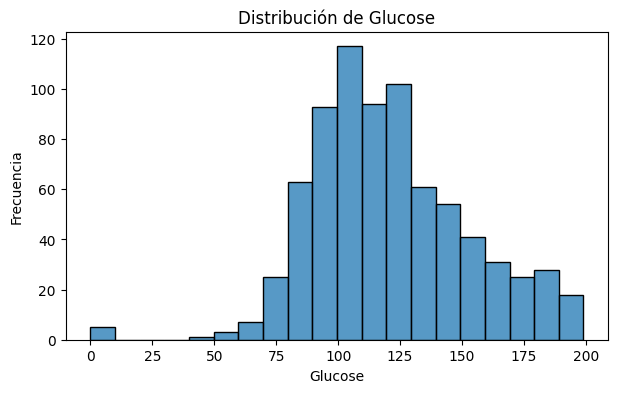

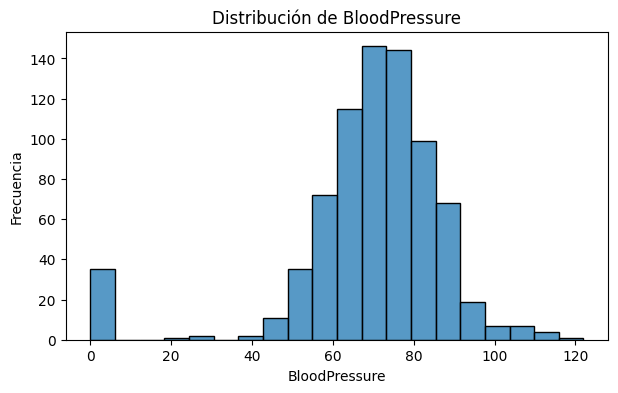

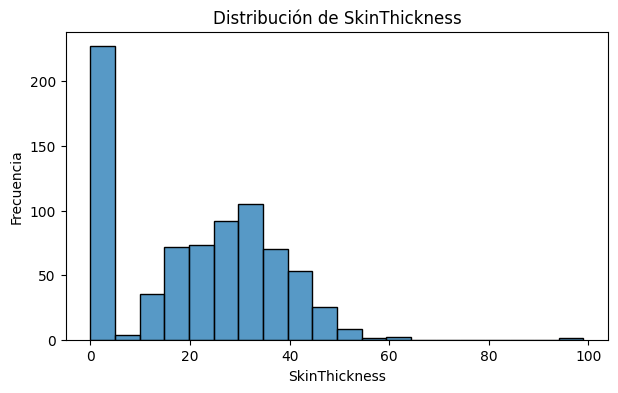

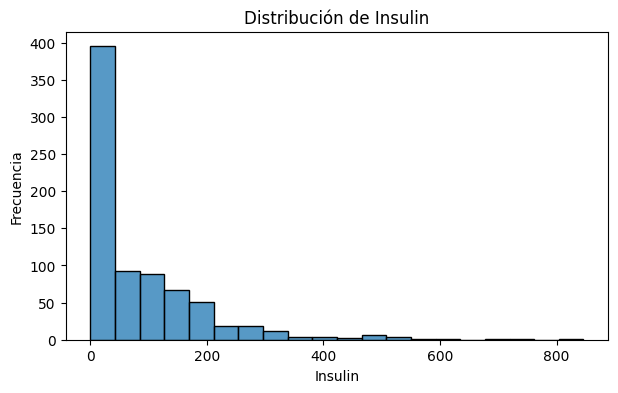

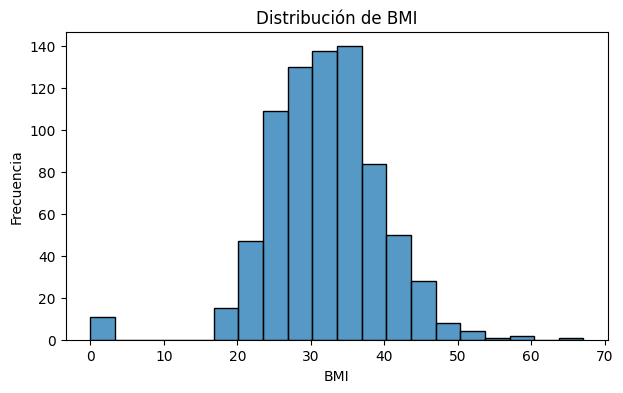

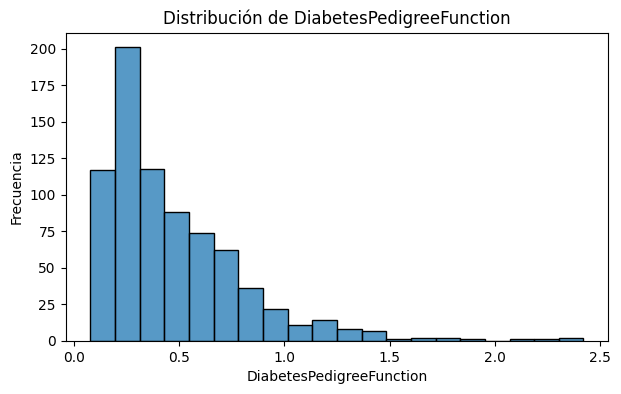

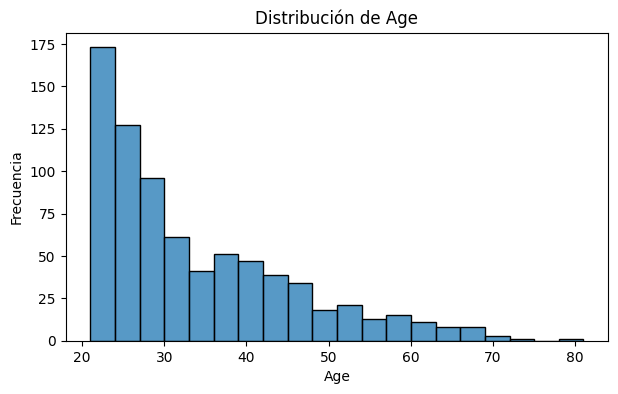

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

variables = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

for variable in variables:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=variable, bins=20)
    plt.title(f"Distribución de {variable}")
    plt.xlabel(variable)
    plt.ylabel("Frecuencia")
    plt.show()

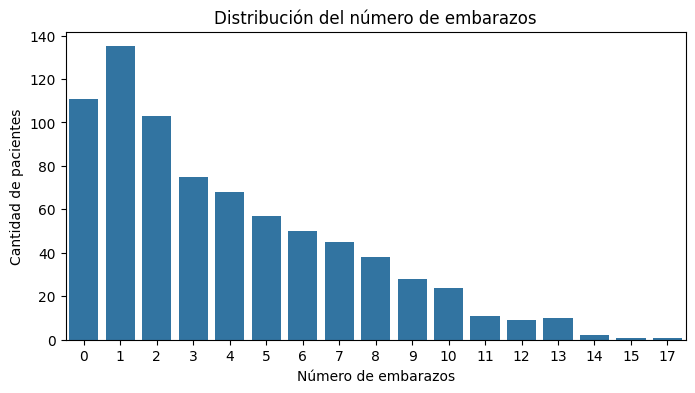

In [ ]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="Pregnancies")
plt.title("Distribución del número de embarazos")
plt.xlabel("Número de embarazos")
plt.ylabel("Cantidad de pacientes")
plt.show()

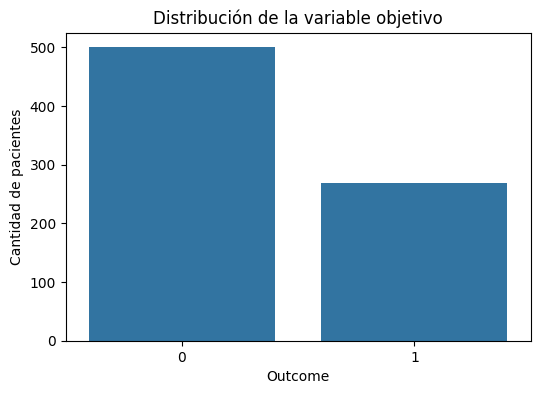

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Outcome")
plt.title("Distribución de la variable objetivo")
plt.xlabel("Outcome")
plt.ylabel("Cantidad de pacientes")
plt.show()

###Boxplots

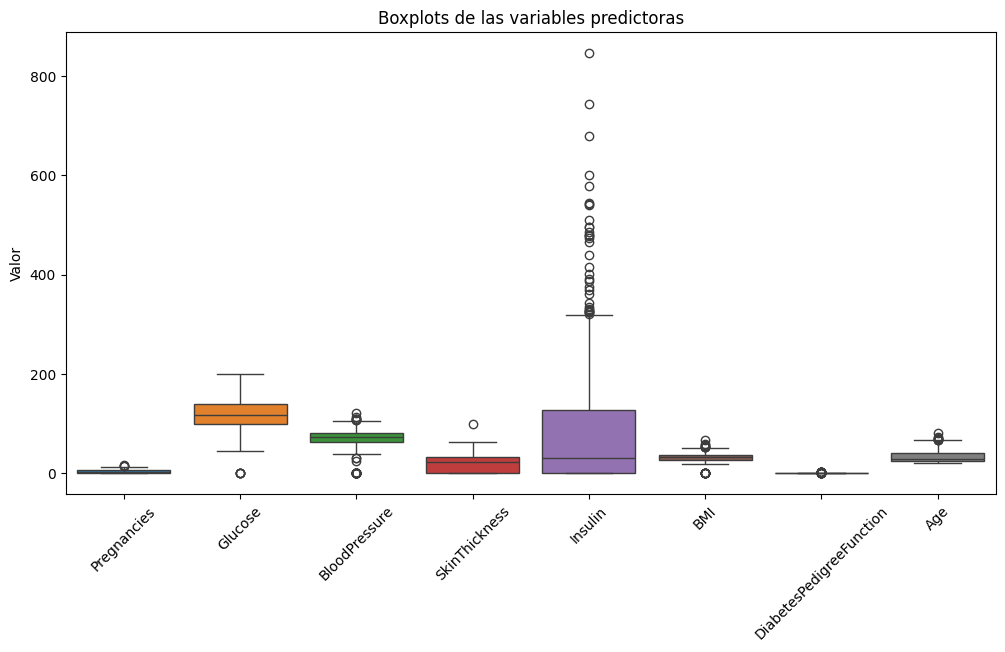

In [ ]:
variables = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[variables])
plt.title("Boxplots de las variables predictoras")
plt.xticks(rotation=45)
plt.ylabel("Valor")
plt.show()

Se observan grandes cantidades de datos atípicos en Insulin, además de ver valores nulos en Glucose, BMI, Bloodpressure, Insulin y SkinThickness. Más adelante se tratarán estos datos.

In [ ]:
porcentaje_ceros = (df == 0).mean() * 100

print(porcentaje_ceros)

Pregnancies                 14.453125
Glucose                      0.651042
BloodPressure                4.557292
SkinThickness               29.557292
Insulin                     48.697917
BMI                          1.432292
DiabetesPedigreeFunction     0.000000
Age                          0.000000
Outcome                     65.104167
dtype: float64


#Análisis bivariado (con la variable Outcome)

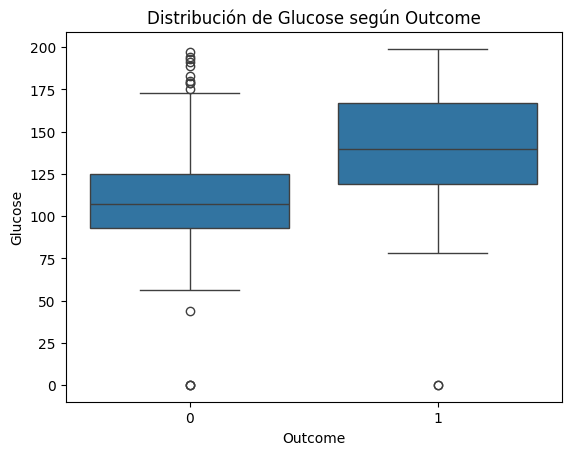

In [ ]:
sns.boxplot(data=df, x="Outcome", y="Glucose")

plt.title("Distribución de Glucose según Outcome")
plt.xlabel("Outcome")
plt.ylabel("Glucose")

plt.show()

In [ ]:
df.groupby("Outcome")["Glucose"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
Outcome,,,,
0,500,109.980000,107.0,26.141200
1,268,141.257463,140.0,31.939622


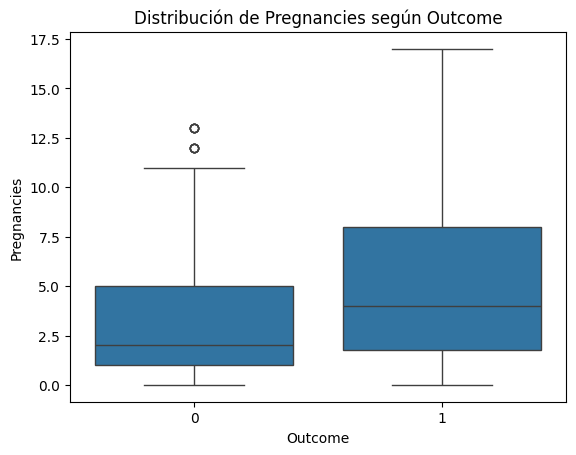

In [ ]:
sns.boxplot(data=df, x="Outcome", y="Pregnancies")

plt.title("Distribución de Pregnancies según Outcome")
plt.xlabel("Outcome")
plt.ylabel("Pregnancies")

plt.show()

In [ ]:
df.groupby("Outcome")["Pregnancies"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
Outcome,,,,
0,500,3.298000,2.0,3.017185
1,268,4.865672,4.0,3.741239


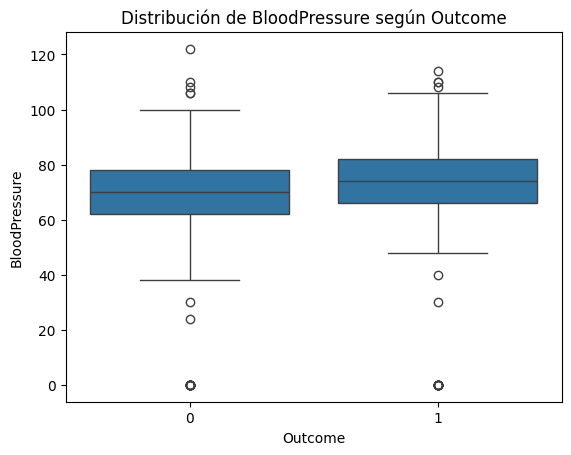

In [ ]:
sns.boxplot(data=df, x="Outcome", y="BloodPressure")

plt.title("Distribución de BloodPressure según Outcome")
plt.xlabel("Outcome")
plt.ylabel("BloodPressure")

plt.show()

In [ ]:
df.groupby("Outcome")["BloodPressure"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
Outcome,,,,
0,500,68.184000,70.0,18.063075
1,268,70.824627,74.0,21.491812


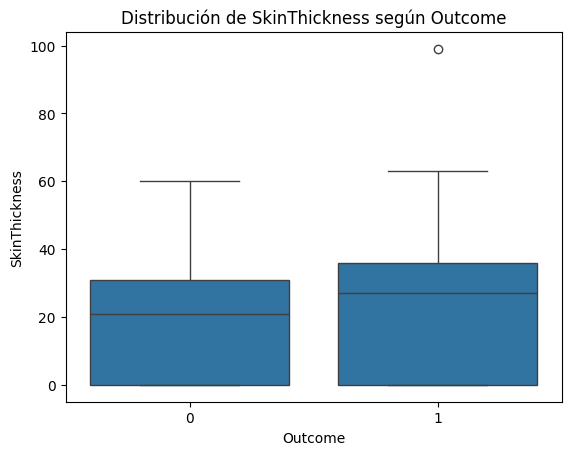

In [ ]:
sns.boxplot(data=df, x="Outcome", y="SkinThickness")

plt.title("Distribución de SkinThickness según Outcome")
plt.xlabel("Outcome")
plt.ylabel("SkinThickness")

plt.show()

In [ ]:
df.groupby("Outcome")["SkinThickness"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
Outcome,,,,
0,500,19.664000,21.0,14.889947
1,268,22.164179,27.0,17.679711


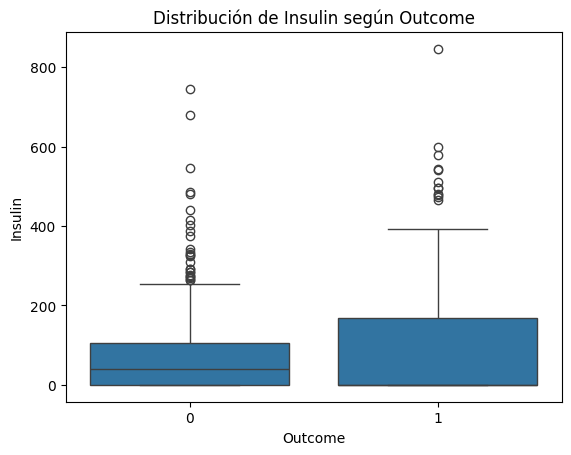

In [ ]:
sns.boxplot(data=df, x="Outcome", y="Insulin")

plt.title("Distribución de Insulin según Outcome")
plt.xlabel("Outcome")
plt.ylabel("Insulin")

plt.show()

In [ ]:
df.groupby("Outcome")["Insulin"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
Outcome,,,,
0,500,68.792000,39.0,98.865289
1,268,100.335821,0.0,138.689125


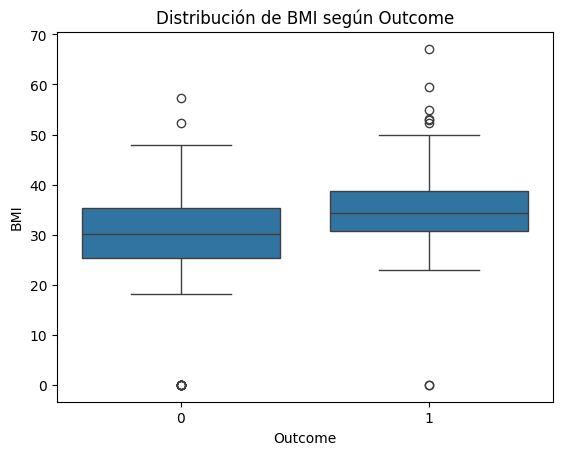

In [ ]:
sns.boxplot(data=df, x="Outcome", y="BMI")

plt.title("Distribución de BMI según Outcome")
plt.xlabel("Outcome")
plt.ylabel("BMI")

plt.show()

In [ ]:
df.groupby("Outcome")["BMI"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
Outcome,,,,
0,500,30.304200,30.05,7.689855
1,268,35.142537,34.25,7.262967


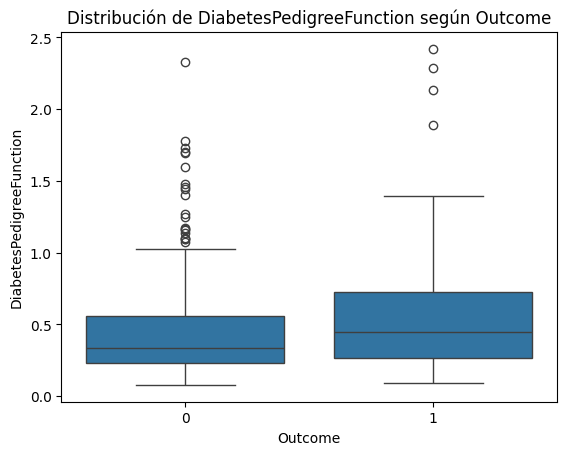

In [ ]:
sns.boxplot(data=df, x="Outcome", y="DiabetesPedigreeFunction")

plt.title("Distribución de DiabetesPedigreeFunction según Outcome")
plt.xlabel("Outcome")
plt.ylabel("DiabetesPedigreeFunction")

plt.show()

In [ ]:
df.groupby("Outcome")["DiabetesPedigreeFunction"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
Outcome,,,,
0,500,0.429734,0.336,0.299085
1,268,0.550500,0.449,0.372354


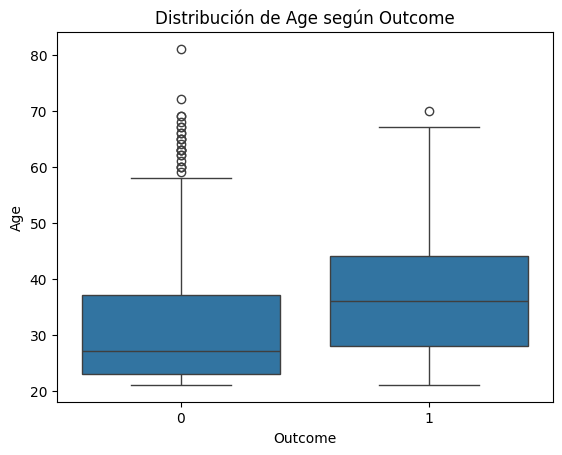

In [ ]:
sns.boxplot(data=df, x="Outcome", y="Age")

plt.title("Distribución de Age según Outcome")
plt.xlabel("Outcome")
plt.ylabel("Age")

plt.show()

In [ ]:
df.groupby("Outcome")["Age"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
Outcome,,,,
0,500,31.190000,27.0,11.667655
1,268,37.067164,36.0,10.968254


#Separamos en train y test

In [ ]:
#Separamos un 80% de los datos para entrenamiento y un 20% restante para testeo.
from sklearn.model_selection import train_test_split

X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

#Tratamiento de datos nulos

In [ ]:
variables_cero = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for variable in variables_cero:
    cantidad = (df[variable] == 0).sum()
    porcentaje = cantidad / len(df) * 100
    print(f"{variable}: {cantidad} ceros ({porcentaje:.2f}%)")

Glucose: 5 ceros (0.65%)
BloodPressure: 35 ceros (4.56%)
SkinThickness: 227 ceros (29.56%)
Insulin: 374 ceros (48.70%)
BMI: 11 ceros (1.43%)


In [ ]:
import numpy as np
variables_cero = ['Glucose', 'BloodPressure',
                  'SkinThickness', 'Insulin', 'BMI']

X_train[variables_cero] = X_train[variables_cero].replace(0, np.nan)
X_test[variables_cero] = X_test[variables_cero].replace(0, np.nan)

In [ ]:
X_train.isnull().sum()

,0
Pregnancies,0
Glucose,4
BloodPressure,23
SkinThickness,175
Insulin,290
BMI,9
DiabetesPedigreeFunction,0
Age,0


In [ ]:
medianas = X_train[variables_cero].median()
medianas

,0
Glucose,117.0
BloodPressure,72.0
SkinThickness,29.0
Insulin,125.0
BMI,32.4


In [ ]:
X_train[variables_cero] = X_train[variables_cero].fillna(medianas)
X_test[variables_cero] = X_test[variables_cero].fillna(medianas)

#Outliers

Para la detección de Outliers, se decidió utilizar el rango intercuartílico. Aquellos valores que se encuentren por debajo de Q1 - 1.5 * IQR serán considerados como outliers, además de aquellos datos que se encuentren por encima de Q3 + 1.5 * IQR.

In [ ]:
#Analicemos el rango intercuartílico de cada variable.
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)

IQR = Q3 - Q1

outliers = ((X_train < (Q1 - 1.5 * IQR)) |
            (X_train > (Q3 + 1.5 * IQR)))

cantidad_outliers = outliers.sum()
porcentaje_outliers = (cantidad_outliers / len(X_train)) * 100

resultado_outliers = pd.DataFrame({
    'Cantidad': cantidad_outliers,
    'Porcentaje': porcentaje_outliers
})

resultado_outliers

,Cantidad,Porcentaje
Pregnancies,2,0.325733
Glucose,0,0.000000
BloodPressure,13,2.117264
SkinThickness,73,11.889251
Insulin,253,41.205212
BMI,7,1.140065
DiabetesPedigreeFunction,19,3.094463
Age,6,0.977199


Se decide mantener los outliers, puesto que datos de glucosa alta, insulina alta, BMI alto, entre otros, pueden representar valores reales y afectar directamente a la presencia de diabetes.

#Modelos de Aprendizaje Automático

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Regresión Logística

In [ ]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(random_state=42)

log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
y_prob = log_reg.predict_proba(X_test_scaled)[:, 1]

In [ ]:
accuracy_log = sk.metrics.accuracy_score(y_test, y_pred)
recall_log = sk.metrics.recall_score(y_test, y_pred)
precision_log = sk.metrics.precision_score(y_test, y_pred)
f1_log = sk.metrics.f1_score(y_test, y_pred)
auc_log = sk.metrics.roc_auc_score(y_test, y_prob)

print("Accuracy:", accuracy_log)
print("Recall:", recall_log)
print("Precision:", precision_log)
print("F1 Score:", f1_log)
print("AUC:", auc_log)

Accuracy: 0.7077922077922078
Recall: 0.5
Precision: 0.6
F1 Score: 0.5454545454545454
AUC: 0.812962962962963


In [ ]:
matriz_log = sk.metrics.confusion_matrix(y_test, y_pred)

matriz_log

array([[82, 18],
       [27, 27]])

Ahora optimicemos los hiperparámetros

In [ ]:
from sklearn.model_selection import GridSearchCV

parametros = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs']
}

In [ ]:
log_reg_cv = GridSearchCV(
    LogisticRegression(random_state=42),
    parametros,
    cv=10,
    scoring='accuracy',
    n_jobs=-1
)

log_reg_cv.fit(X_train_scaled, y_train)

GridSearchCV(cv=10, estimator=LogisticRegression(random_state=42), n_jobs=-1,
             param_grid={'C': [0.001, 0.01, 0.1, 1, 10, 100],
                         'solver': ['liblinear', 'lbfgs']},
             scoring='accuracy')

In [ ]:
log_reg_opt = log_reg_cv.best_estimator_

In [ ]:
y_pred_log_opt = log_reg_opt.predict(X_test_scaled)

y_prob_log_opt = log_reg_opt.predict_proba(X_test_scaled)[:, 1]

In [ ]:
accuracy_log_opt = sk.metrics.accuracy_score(y_test, y_pred_log_opt)
recall_log_opt = sk.metrics.recall_score(y_test, y_pred_log_opt)
precision_log_opt = sk.metrics.precision_score(y_test, y_pred_log_opt)
f1_log_opt = sk.metrics.f1_score(y_test, y_pred_log_opt)
auc_log_opt = sk.metrics.roc_auc_score(y_test, y_prob_log_opt)

print("Accuracy:", accuracy_log_opt)
print("Recall:", recall_log_opt)
print("Precision:", precision_log_opt)
print("F1 Score:", f1_log_opt)
print("AUC:", auc_log_opt)

Accuracy: 0.6883116883116883
Recall: 0.48148148148148145
Precision: 0.5652173913043478
F1 Score: 0.52
AUC: 0.8103703703703704


##Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

In [ ]:
accuracy_rf = sk.metrics.accuracy_score(y_test, y_pred_rf)
recall_rf = sk.metrics.recall_score(y_test, y_pred_rf)
precision_rf = sk.metrics.precision_score(y_test, y_pred_rf)
f1_rf = sk.metrics.f1_score(y_test, y_pred_rf)
auc_rf = sk.metrics.roc_auc_score(y_test, y_prob_rf)

print("Accuracy:", accuracy_rf)
print("Recall:", recall_rf)
print("Precision:", precision_rf)
print("F1 Score:", f1_rf)
print("AUC:", auc_rf)

Accuracy: 0.7402597402597403
Recall: 0.5555555555555556
Precision: 0.6521739130434783
F1 Score: 0.6
AUC: 0.8167592592592593


In [ ]:
matriz_rf = sk.metrics.confusion_matrix(y_test, y_pred_rf)

matriz_rf

array([[84, 16],
       [24, 30]])

Optimizamos hiperparámetros

In [ ]:
parametros_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

In [ ]:
rf_cv = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    parametros_rf,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

rf_cv.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [None, 5, 10, 20],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]},
             scoring='roc_auc')

In [ ]:
print(rf_cv.best_params_)
print(rf_cv.best_score_)

{'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 300}
0.8400456810631229


In [ ]:
rf_opt = rf_cv.best_estimator_

y_pred_rf_opt = rf_opt.predict(X_test)
y_prob_rf_opt = rf_opt.predict_proba(X_test)[:, 1]

In [ ]:
accuracy_rf_opt = sk.metrics.accuracy_score(y_test, y_pred_rf_opt)
recall_rf_opt = sk.metrics.recall_score(y_test, y_pred_rf_opt)
precision_rf_opt = sk.metrics.precision_score(y_test, y_pred_rf_opt)
f1_rf_opt = sk.metrics.f1_score(y_test, y_pred_rf_opt)
auc_rf_opt = sk.metrics.roc_auc_score(y_test, y_prob_rf_opt)

print("Accuracy:", accuracy_rf_opt)
print("Recall:", recall_rf_opt)
print("Precision:", precision_rf_opt)
print("F1 Score:", f1_rf_opt)
print("AUC:", auc_rf_opt)

Accuracy: 0.7467532467532467
Recall: 0.5370370370370371
Precision: 0.6744186046511628
F1 Score: 0.5979381443298969
AUC: 0.8061111111111111


##Gradient Boosting

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(random_state=42)

gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)
y_prob_gb = gb.predict_proba(X_test)[:, 1]

In [ ]:
accuracy_gb = sk.metrics.accuracy_score(y_test, y_pred_gb)
recall_gb = sk.metrics.recall_score(y_test, y_pred_gb)
precision_gb = sk.metrics.precision_score(y_test, y_pred_gb)
f1_gb = sk.metrics.f1_score(y_test, y_pred_gb)
auc_gb = sk.metrics.roc_auc_score(y_test, y_prob_gb)

print("Accuracy:", accuracy_gb)
print("Recall:", recall_gb)
print("Precision:", precision_gb)
print("F1 Score:", f1_gb)
print("AUC:", auc_gb)

Accuracy: 0.7597402597402597
Recall: 0.5740740740740741
Precision: 0.6888888888888889
F1 Score: 0.6262626262626263
AUC: 0.8314814814814814


In [ ]:
matriz_gb = sk.metrics.confusion_matrix(y_test, y_pred_gb)

matriz_gb

array([[86, 14],
       [23, 31]])

Optimizamos hiperparámetros

In [ ]:
from sklearn.model_selection import GridSearchCV

parametros_gb = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [2, 3, 5],
    'min_samples_leaf': [1, 2, 5]
}

In [ ]:
gb_cv = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    parametros_gb,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

gb_cv.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=GradientBoostingClassifier(random_state=42),
             n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.1, 0.2],
                         'max_depth': [2, 3, 5], 'min_samples_leaf': [1, 2, 5],
                         'n_estimators': [50, 100, 200]},
             scoring='roc_auc')

In [ ]:
print(gb_cv.best_params_)
print(gb_cv.best_score_)

{'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 2, 'n_estimators': 50}
0.8315822259136212


In [ ]:
gb_opt = gb_cv.best_estimator_

y_pred_gb_opt = gb_opt.predict(X_test)
y_prob_gb_opt = gb_opt.predict_proba(X_test)[:, 1]

accuracy_gb_opt = sk.metrics.accuracy_score(y_test, y_pred_gb_opt)
recall_gb_opt = sk.metrics.recall_score(y_test, y_pred_gb_opt)
precision_gb_opt = sk.metrics.precision_score(y_test, y_pred_gb_opt)
f1_gb_opt = sk.metrics.f1_score(y_test, y_pred_gb_opt)
auc_gb_opt = sk.metrics.roc_auc_score(y_test, y_prob_gb_opt)

print("Accuracy:", accuracy_gb_opt)
print("Recall:", recall_gb_opt)
print("Precision:", precision_gb_opt)
print("F1 Score:", f1_gb_opt)
print("AUC:", auc_gb_opt)

Accuracy: 0.7467532467532467
Recall: 0.5370370370370371
Precision: 0.6744186046511628
F1 Score: 0.5979381443298969
AUC: 0.820925925925926


#Comparativa de modelos

In [ ]:
resultados = pd.DataFrame({
    'Modelo': ['Regresión Logística', 'Random Forest', 'Gradient Boosting'],
    'Accuracy': [accuracy_log, accuracy_rf, accuracy_gb],
    'Recall': [recall_log, recall_rf, recall_gb],
    'Precision': [precision_log, precision_rf, precision_gb],
    'F1 Score': [f1_log, f1_rf, f1_gb],
    'AUC': [auc_log, auc_rf, auc_gb]
})

resultados

,Modelo,Accuracy,Recall,Precision,F1 Score,AUC
0,Regresión Logística,0.707792,0.500000,0.600000,0.545455,0.812963
1,Random Forest,0.740260,0.555556,0.652174,0.600000,0.816759
2,Gradient Boosting,0.759740,0.574074,0.688889,0.626263,0.831481


In [ ]:
resultados_opt = pd.DataFrame({

    'Modelo': ['Regresión Logística', 'Random Forest', 'Gradient Boosting'],

    'Accuracy': [accuracy_log_opt, accuracy_rf_opt, accuracy_gb_opt],

    'Recall': [recall_log_opt, recall_rf_opt, recall_gb_opt],

    'Precision': [precision_log_opt, precision_rf_opt, precision_gb_opt],

    'F1 Score': [f1_log_opt, f1_rf_opt, f1_gb_opt],

    'AUC': [auc_log_opt, auc_rf_opt, auc_gb_opt]

})

resultados_opt

,Modelo,Accuracy,Recall,Precision,F1 Score,AUC
0,Regresión Logística,0.688312,0.481481,0.565217,0.520000,0.810370
1,Random Forest,0.746753,0.537037,0.674419,0.597938,0.806111
2,Gradient Boosting,0.746753,0.537037,0.674419,0.597938,0.820926


#SHAP

In [ ]:
!pip install shap

In [ ]:
import shap

In [ ]:
explainer = shap.Explainer(gb, X_train)

In [ ]:
shap_values = explainer(X_test)

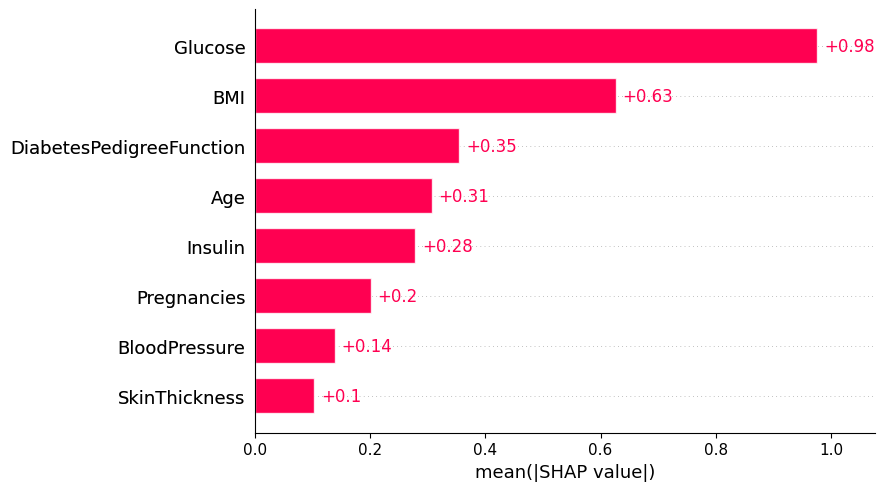

In [ ]:
shap.plots.bar(shap_values)

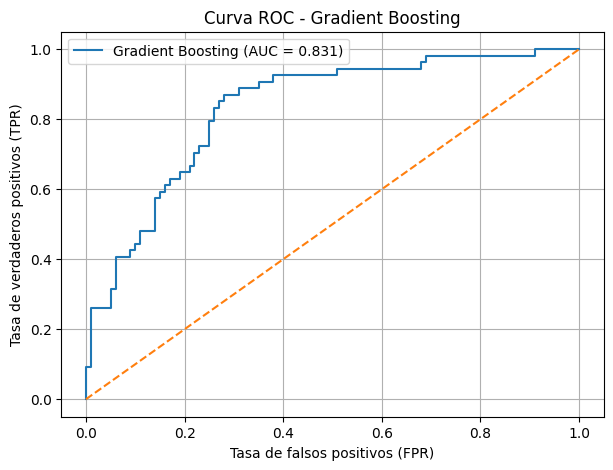

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

y_prob = gb.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'Gradient Boosting (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('Tasa de falsos positivos (FPR)')
plt.ylabel('Tasa de verdaderos positivos (TPR)')
plt.title('Curva ROC - Gradient Boosting')
plt.legend()
plt.grid()
plt.show()